# Burnt scar visualization — Siverskyi Donets, east of Luhansk (October 2020)

Runs the `wildfire_visualization` UDP (Sentinel-2 L2A true colour with a square-root stretch; pixels with NBR < -0.25 get a +0.3 red/green boost so the burnt scars show as orange-yellow) on CDSE over the late-September 2020 wildfires along the Siverskyi Donets river, then plots the result.

Scenes picked up by the window (openEO end dates are exclusive; the UDP keeps only scenes with ≤ 30% cloud and uses the first one):

| Window | Sentinel-2 L2A scenes (tile cloud cover) | Used |
|---|---|---|
| 2020-09-30 → 2020-10-06 | 2020-09-30 (45–78%), 2020-10-02 (79–93%), 2020-10-05 (1%) | 2020-10-05 |

In [1]:
from pathlib import Path

import openeo

connection = openeo.connect("https://openeo.dataspace.copernicus.eu/").authenticate_oidc()

Authenticated using refresh token.


In [2]:
# Bounding box and temporal extent
shape = {"west": 39.4750, "south": 48.5626, "east": 39.6472, "north": 48.6704}
start_date, end_date = ["2020-09-30", "2020-10-06"]

public_url = "https://raw.githubusercontent.com/ESA-APEx/apex_algorithms/main/algorithm_catalog/developmentseed/wildfire_visualization/openeo_udp/wildfire_visualization.json"

# The process id must match the "id" in the UDP JSON at public_url.
process_id = "wildfire_visualization"

output = Path("wildfire_visualization_luhansk.tiff")

In [3]:
burnt_scar_luhansk = connection.datacube_from_process(
    process_id,
    namespace=public_url,
    time=[start_date, end_date],
    bounding_box=shape,
    cloud_cover=30,
)

## Burnt scar visualization

In [4]:
job = burnt_scar_luhansk.create_job(
    title=f"Burnt scar visualization for {start_date} to {end_date}",
    out_format="GTiff",
)
job.start_and_wait()

0:00:00 Job 'j-2610271815354a3bb7966cbb43af957e': send 'start'
0:00:02 Job 'j-2610271815354a3bb7966cbb43af957e': created (progress 0%)
0:00:07 Job 'j-2610271815354a3bb7966cbb43af957e': queued (progress 0%)
0:00:13 Job 'j-2610271815354a3bb7966cbb43af957e': queued (progress 0%)
0:00:22 Job 'j-2610271815354a3bb7966cbb43af957e': queued (progress 0%)
0:00:32 Job 'j-2610271815354a3bb7966cbb43af957e': queued (progress 0%)
0:00:45 Job 'j-2610271815354a3bb7966cbb43af957e': running (progress N/A)
0:01:00 Job 'j-2610271815354a3bb7966cbb43af957e': running (progress N/A)
0:01:19 Job 'j-2610271815354a3bb7966cbb43af957e': running (progress N/A)
0:01:43 Job 'j-2610271815354a3bb7966cbb43af957e': finished (progress 100%)


<BatchJob job_id='j-2610271815354a3bb7966cbb43af957e'>

In [5]:
# The result is a single 3-band GeoTIFF. If the download breaks, rerun only
# this cell; the job does not need to be resubmitted.
job.get_results().download_file(output)

PosixPath('wildfire_visualization_luhansk.tiff')

## Burnt scars

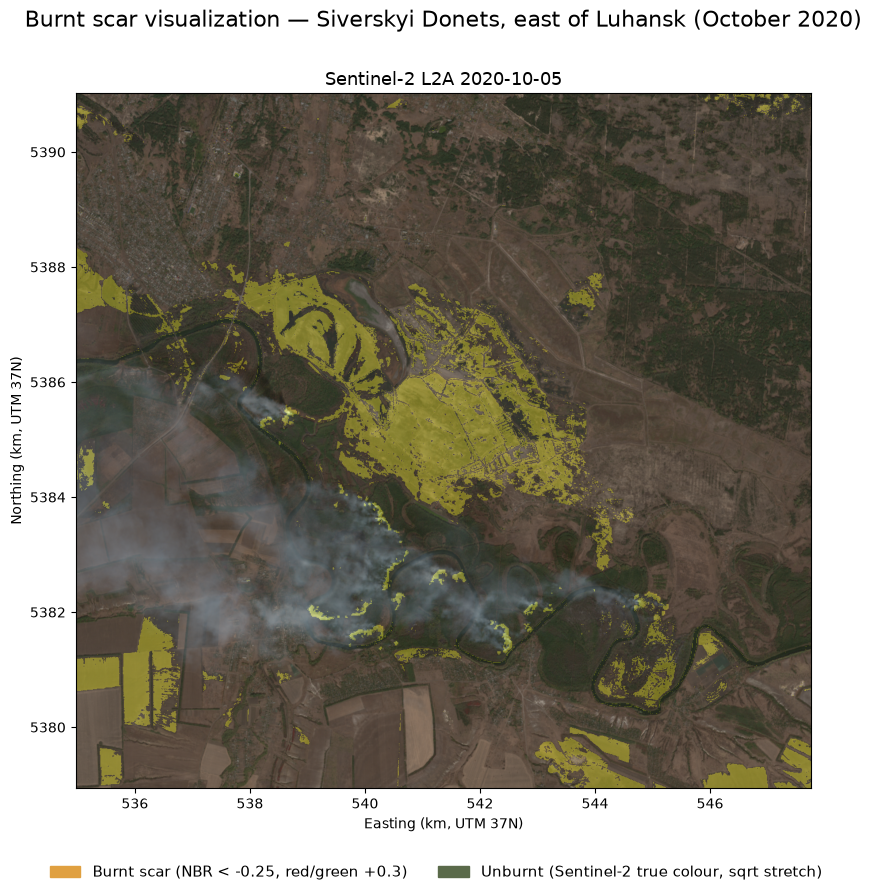

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import rasterio
from matplotlib.patches import Patch


def read_rgb(path):
    """Read a 3-band wildfire_visualization GeoTIFF as an (H, W, 3) 0-1 array plus its extent in km."""
    with rasterio.open(path) as src:
        data = src.read()
        b = src.bounds
    # The UDP output is already display-scaled (sqrt stretch); burnt pixels can
    # exceed 1 after the +0.3 boost, so clip to 0-1.
    rgb = np.clip(np.nan_to_num(np.moveaxis(data, 0, -1)), 0, 1)
    extent = [b.left / 1000, b.right / 1000, b.bottom / 1000, b.top / 1000]
    return rgb, extent


rgb, extent = read_rgb(output)

fig, ax = plt.subplots(figsize=(12, 9))
ax.imshow(rgb, extent=extent)
ax.set_title("Sentinel-2 L2A 2020-10-05", fontsize=13)
ax.set_xlabel("Easting (km, UTM 37N)")
ax.set_ylabel("Northing (km, UTM 37N)")

fig.legend(
    handles=[
        Patch(color="#e0a040", label="Burnt scar (NBR < -0.25, red/green +0.3)"),
        Patch(color="#5a6a4a", label="Unburnt (Sentinel-2 true colour, sqrt stretch)"),
    ],
    loc="lower center",
    ncol=2,
    frameon=False,
    fontsize=11,
)
fig.suptitle("Burnt scar visualization — Siverskyi Donets, east of Luhansk (October 2020)", fontsize=16)
fig.tight_layout(rect=(0, 0.05, 1, 0.97))
fig.savefig("wildfire_visualization_luhansk.png", dpi=200)
plt.show()